# Forecasting tomorrow's Saudi Aramco share price

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/snow10100/aie113-projects/blob/main/tracks/stocks/notebook.ipynb)

This notebook downloads five years of real daily prices of Saudi Aramco (`2222.SR`) on the Saudi Exchange (Tadawul) and trains a small, explainable model that guesses the next trading day's closing price from the last few weeks of prices. We always compare it with the simplest possible guess, "tomorrow's price = today's price", and we show which inputs pushed a forecast up or down.

**This is a teaching example, not investment advice.** Do not use it to buy or sell anything.

The model is explained in plain words in [README.md](README.md) (English) and [README.ar.md](README.ar.md) (العربية).

## 1. Install what is missing
Colab already has almost everything; there we only update `yfinance`, the library that downloads prices from Yahoo Finance, because Yahoo changes its site often. On your own computer, `requirements.txt` installs everything.

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q --upgrade yfinance
else:
    print("Running locally: packages come from requirements.txt")

Running locally: packages come from requirements.txt


## 2. Settings
Every choice of this notebook in one place: which share, which dates, where the test period starts and where the model is saved. The dates are fixed so that everyone gets the same numbers; move `END_DATE` forward to use fresher prices.

In [2]:
import json
import os
import time
from datetime import datetime, timezone

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import yfinance as yf
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

TICKER = "2222.SR"           # Saudi Aramco on Tadawul (Yahoo Finance symbol)
START_DATE = "2021-11-01"    # about five years of history
END_DATE = "2026-11-01"      # Yahoo stops the day before this date
TEST_START = "2025-11-01"    # the last 12 months are kept for the final test
ALPHAS = [0.1, 1, 10, 100, 1000, 3000, 10000]   # how strongly the model is held back (picked in step 7)
RANDOM_SEED = 42
MODEL_VERSION = "stocks-ridge-1.0.0"
MODEL_PATH = "artifacts/model.joblib"
META_PATH = "artifacts/model_meta.json"

np.random.seed(RANDOM_SEED)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e4e0", "grid.linewidth": 0.6})
print("yfinance", yf.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

yfinance 1.8.0 | scikit-learn 1.9.1 | pandas 3.1.1


## 3. Download the prices
We ask Yahoo Finance for one row per trading day: open, high, low, close, volume, dividends and bonus shares. Yahoo sometimes refuses a request, so we try twice before giving up.

In [3]:
raw = pd.DataFrame()
for attempt in [1, 2]:
    try:
        raw = yf.Ticker(TICKER).history(start=START_DATE, end=END_DATE, auto_adjust=False)
    except Exception as e:
        print("Download failed:", e)
    if len(raw) > 0:
        break
    if attempt == 1:
        print("No data received, trying again in 10 seconds ...")
        time.sleep(10)

if len(raw) == 0:
    raise RuntimeError("Yahoo Finance sent no data for " + TICKER + ". Check the internet connection and try again later.")

raw.index = raw.index.tz_localize(None)   # Yahoo gives Riyadh time; we only need the date
print(raw.shape)
raw.head(3)

(1246, 8)


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
Date,,,,,,,,
2021-11-01,31.322313,31.404959,31.198347,31.198347,24.285154,6283290,0.0,0.0
2021-11-02,31.198347,31.322313,31.115702,31.322313,24.381653,6159783,0.0,0.0
2021-11-03,31.280991,31.280991,31.033056,31.074381,24.188658,3852292,0.0,0.0


## 4. A quick look at the data
Aramco trades Sunday to Thursday, and Yahoo's prices are already corrected for the bonus shares of 2022 and 2023, so old and new prices can be compared. Rows with zero volume and a flat price are days where Yahoo recorded no trading, so we drop them. We keep only the closing price: Yahoo's volume numbers are clearly wrong for a few months in 2023.

Rows downloaded: 1246 from 2021-11-01 to 2026-10-29
Trading days per weekday: {'Monday': 250, 'Wednesday': 250, 'Thursday': 250, 'Tuesday': 249, 'Sunday': 247}
Rows with zero volume (no trading recorded): 31
Bonus-share dates (1 new share for every 10): ['2022-05-15', '2023-05-09']
Rows kept: 1215
count    1215.00
mean       29.36
std         3.58
min        23.13
25%        26.47
50%        28.68
75%        32.30
max        38.64
Name: Close, dtype: float64


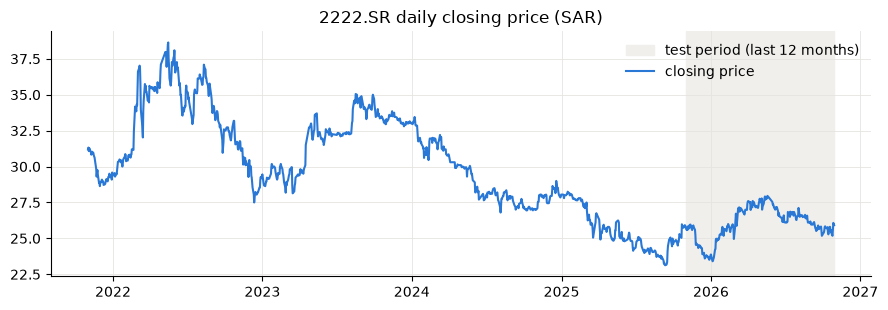

In [4]:
print("Rows downloaded:", len(raw), "from", raw.index.min().date(), "to", raw.index.max().date())
print("Trading days per weekday:", raw.index.day_name().value_counts().to_dict())
print("Rows with zero volume (no trading recorded):", int((raw["Volume"] == 0).sum()))
print("Bonus-share dates (1 new share for every 10):", [d.date().isoformat() for d in raw.index[raw["Stock Splits"] > 0]])

prices = raw.loc[raw["Volume"] > 0, ["Close"]].dropna()
print("Rows kept:", len(prices))
print(prices["Close"].describe().round(2))

plt.figure(figsize=(9, 3.2))
plt.axvspan(pd.Timestamp(TEST_START), prices.index.max(), color="#f0efec", label="test period (last 12 months)")
plt.plot(prices.index, prices["Close"], color="#2a78d6", linewidth=1.5, label="closing price")
plt.title(TICKER + " daily closing price (SAR)")
plt.legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.show()

## 5. Build the inputs (features)
For every day we describe the recent past with a few numbers: today's move, the moves of the two days before, the move over the last week, how far the price sits from its 5-day and 20-day averages, how jumpy the last 10 days were, and the weekday. The target is tomorrow's move in percent; we turn it back into a price later.

In [5]:
data = prices.copy()
close = data["Close"]
daily_return = close.pct_change()

data["ret_1d"] = daily_return                            # today's move (0.01 = +1%)
data["ret_lag1"] = daily_return.shift(1)                 # yesterday's move
data["ret_lag2"] = daily_return.shift(2)                 # the move two days ago
data["ret_5d"] = close / close.shift(5) - 1              # the move over the last 5 trading days
data["gap_ma5"] = close / close.rolling(5).mean() - 1    # distance from the 5-day average
data["gap_ma20"] = close / close.rolling(20).mean() - 1  # distance from the 20-day average
data["vol_10d"] = daily_return.rolling(10).std()         # how jumpy the last 10 days were
data["day_of_week"] = (data.index.day_of_week + 1) % 7   # 0 = Sunday ... 4 = Thursday

data["next_close"] = close.shift(-1)                     # what we want to predict ...
data["target"] = data["next_close"] / close - 1          # ... written as a move from today's close

FEATURES = ["ret_1d", "ret_lag1", "ret_lag2", "ret_5d", "gap_ma5", "gap_ma20", "vol_10d", "day_of_week"]
data[FEATURES + ["target"]].tail().round(4)

,ret_1d,ret_lag1,ret_lag2,ret_5d,gap_ma5,gap_ma20,vol_10d,day_of_week,target
Date,,,,,,,,,
2026-10-25,-0.0087,-0.0070,0.0039,-0.0240,-0.0121,-0.0139,0.0102,0,0.0167
2026-10-26,0.0167,-0.0087,-0.0070,-0.0078,0.0060,0.0024,0.0118,1,0.0187
2026-10-27,0.0187,0.0167,-0.0087,0.0235,0.0200,0.0194,0.0133,2,-0.0031
2026-10-28,-0.0031,0.0187,0.0167,0.0164,0.0136,0.0147,0.0121,3,-0.0031
2026-10-29,-0.0031,-0.0031,0.0187,0.0205,0.0064,0.0103,0.0120,4,NaN


## 6. Split by time: older years to learn, the last 12 months to test
The model learns only from the older years and is tested on the last 12 months, which it never sees while learning. We never shuffle the days, because that would let the model peek at the future. The first weeks (not enough history yet) and the very last day (its tomorrow is unknown) are left out.

In [6]:
model_data = data.dropna()
train = model_data[model_data.index < TEST_START]
test = model_data[model_data.index >= TEST_START]

X_train, y_train = train[FEATURES], train["target"]
X_test, y_test = test[FEATURES], test["target"]
print("Train:", len(train), "days,", train.index.min().date(), "to", train.index.max().date())
print("Test: ", len(test), "days,", test.index.min().date(), "to", test.index.max().date())

Train: 950 days, 2021-11-29 to 2025-10-30
Test:  245 days, 2025-11-02 to 2026-10-28


## 7. Train the model
We use ridge regression: it gives each input a weight and adds them up, and it is held back so that it does not chase noise. How strongly it is held back is chosen inside the training years only, always learning on earlier days and checking on later ones.

In [7]:
search = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    param_grid={"ridge__alpha": ALPHAS},
    cv=TimeSeriesSplit(n_splits=5),
    scoring="neg_mean_absolute_error",
)
search.fit(X_train, y_train)
model = search.best_estimator_

checks = pd.Series(-search.cv_results_["mean_test_score"] * 100, index=ALPHAS, name="avg error of tomorrow's move (%)")
print(checks.round(4))
print("Chosen alpha:", search.best_params_["ridge__alpha"])

0.1        0.6675
1.0        0.6663
10.0       0.6637
100.0      0.6546
1000.0     0.6460
3000.0     0.6463
10000.0    0.6468
Name: avg error of tomorrow's move (%), dtype: float64
Chosen alpha: 1000


## 8. Is it any good? Compare with the naive guess
The naive guess says "tomorrow's close = today's close". On the 12 test months we measure how far each forecast lands from the real closing price on average (in SAR), and how often the model at least gets the direction right. Expect a sobering result: for a big, busy share, today's price is very hard to beat.

                         MAE (SAR)  RMSE (SAR)  MAPE (%)
ridge model                 0.1732      0.2436    0.6655
naive: tomorrow = today     0.1712      0.2408    0.6580
Model vs naive: -1.17% on the average error (positive = the model is better)
Direction right on 51.3% of the 226 test days when the price moved (a coin flip gets about 50%)


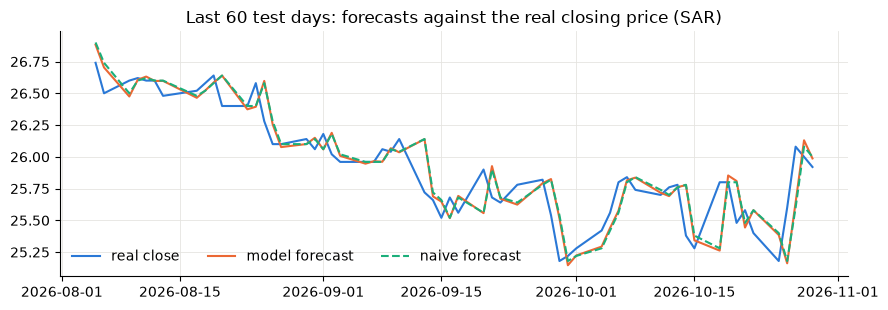

In [8]:
test_pred_return = pd.Series(model.predict(X_test), index=test.index)
test_pred_price = test["Close"] * (1 + test_pred_return)
naive_price = test["Close"]
actual_price = test["next_close"]

model_mae = (actual_price - test_pred_price).abs().mean()
naive_mae = (actual_price - naive_price).abs().mean()
model_rmse = np.sqrt(((actual_price - test_pred_price) ** 2).mean())
naive_rmse = np.sqrt(((actual_price - naive_price) ** 2).mean())
model_mape = ((actual_price - test_pred_price).abs() / actual_price).mean() * 100
naive_mape = ((actual_price - naive_price).abs() / actual_price).mean() * 100
improvement = (1 - model_mae / naive_mae) * 100
moved = y_test != 0
direction_hit = (np.sign(test_pred_return[moved]) == np.sign(y_test[moved])).mean() * 100

results = pd.DataFrame(
    {"MAE (SAR)": [model_mae, naive_mae], "RMSE (SAR)": [model_rmse, naive_rmse], "MAPE (%)": [model_mape, naive_mape]},
    index=["ridge model", "naive: tomorrow = today"],
)
print(results.round(4))
print(f"Model vs naive: {improvement:+.2f}% on the average error (positive = the model is better)")
print(f"Direction right on {direction_hit:.1f}% of the {int(moved.sum())} test days when the price moved (a coin flip gets about 50%)")

forecast_day = data.index.to_series().shift(-1).loc[test.index]   # the day each forecast is for
last = slice(-60, None)
plt.figure(figsize=(9, 3.2))
plt.plot(forecast_day.iloc[last], actual_price.iloc[last], color="#2a78d6", linewidth=1.5, label="real close")
plt.plot(forecast_day.iloc[last], test_pred_price.iloc[last], color="#eb6834", linewidth=1.5, label="model forecast")
plt.plot(forecast_day.iloc[last], naive_price.iloc[last], color="#1baf7a", linewidth=1.5, linestyle="--", label="naive forecast")
plt.title("Last 60 test days: forecasts against the real closing price (SAR)")
plt.legend(loc="lower left", frameon=False, ncol=3)
plt.tight_layout()
plt.show()

## 9. Save the model and its facts
A service needs two things from us: the trained model file, and a small file of facts about it (version, inputs, dates, test numbers). Both go into `artifacts/`.

In [9]:
os.makedirs("artifacts", exist_ok=True)
joblib.dump(model, MODEL_PATH)

meta = {
    "model_version": MODEL_VERSION,
    "ticker": TICKER,
    "target": "next trading day's closing price in SAR, predicted as a move from today's close",
    "features": FEATURES,
    "ridge_alpha": search.best_params_["ridge__alpha"],
    "data_source": "Yahoo Finance via yfinance, daily Close adjusted for bonus shares, rows with zero volume dropped",
    "train": {"start": str(train.index.min().date()), "end": str(train.index.max().date()), "rows": len(train)},
    "test": {"start": str(test.index.min().date()), "end": str(test.index.max().date()), "rows": len(test)},
    "metrics_test": {
        "model": {"mae_sar": round(float(model_mae), 4), "rmse_sar": round(float(model_rmse), 4),
                  "mape_pct": round(float(model_mape), 4), "direction_hit_pct": round(float(direction_hit), 2)},
        "naive_baseline": {"mae_sar": round(float(naive_mae), 4), "rmse_sar": round(float(naive_rmse), 4),
                           "mape_pct": round(float(naive_mape), 4)},
        "mae_improvement_vs_naive_pct": round(float(improvement), 2),
    },
    "sklearn_version": sklearn.__version__,
    "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}
with open(META_PATH, "w") as f:
    json.dump(meta, f, indent=2)

print(json.dumps(meta, indent=2))
print("Model file:", MODEL_PATH, os.path.getsize(MODEL_PATH), "bytes")

{
  "model_version": "stocks-ridge-1.0.0",
  "ticker": "2222.SR",
  "target": "next trading day's closing price in SAR, predicted as a move from today's close",
  "features": [
    "ret_1d",
    "ret_lag1",
    "ret_lag2",
    "ret_5d",
    "gap_ma5",
    "gap_ma20",
    "vol_10d",
    "day_of_week"
  ],
  "ridge_alpha": 1000,
  "data_source": "Yahoo Finance via yfinance, daily Close adjusted for bonus shares, rows with zero volume dropped",
  "train": {
    "start": "2021-11-29",
    "end": "2025-10-30",
    "rows": 950
  },
  "test": {
    "start": "2025-11-02",
    "end": "2026-10-28",
    "rows": 245
  },
  "metrics_test": {
    "model": {
      "mae_sar": 0.1732,
      "rmse_sar": 0.2436,
      "mape_pct": 0.6655,
      "direction_hit_pct": 51.33
    },
    "naive_baseline": {
      "mae_sar": 0.1712,
      "rmse_sar": 0.2408,
      "mape_pct": 0.658
    },
    "mae_improvement_vs_naive_pct": -1.17
  },
  "sklearn_version": "1.9.1",
  "created_at": "2026-11-24T01:16:56+00:00"
}
Mo

## 10. Score one example: the forecast for the next trading day
This is what a service would do: take the latest prices, build the same inputs, load the saved model and turn its answer into a price. The input code repeats step 5 for one day; the last line checks that both give the same numbers.

In [10]:
loaded_model = joblib.load(MODEL_PATH)

recent = prices.tail(30).copy()   # 30 trading days are enough for every input
recent_close = recent["Close"]
recent_return = recent_close.pct_change()
recent["ret_1d"] = recent_return
recent["ret_lag1"] = recent_return.shift(1)
recent["ret_lag2"] = recent_return.shift(2)
recent["ret_5d"] = recent_close / recent_close.shift(5) - 1
recent["gap_ma5"] = recent_close / recent_close.rolling(5).mean() - 1
recent["gap_ma20"] = recent_close / recent_close.rolling(20).mean() - 1
recent["vol_10d"] = recent_return.rolling(10).std()
recent["day_of_week"] = (recent.index.day_of_week + 1) % 7
example = recent[FEATURES].tail(1)

last_date = example.index[0]
last_close = recent_close.iloc[-1]
pred_return = loaded_model.predict(example)[0]
pred_price = last_close * (1 + pred_return)

print(example.T.round(5))
print(f"Last close: {last_close:.2f} SAR on {last_date.date()} ({last_date.day_name()})")
print(f"Model forecast for the next trading day: {pred_price:.3f} SAR ({pred_return * 100:+.3f}%, {(pred_price - last_close) * 100:+.2f} halalas)")
print(f"Naive forecast: {last_close:.2f} SAR")
print("Same inputs as step 5:", np.allclose(example.values, data[FEATURES].tail(1).values))

Date         2026-10-29
ret_1d         -0.00308
ret_lag1       -0.00307
ret_lag2        0.01875
ret_5d          0.02047
gap_ma5         0.00637
gap_ma20        0.01033
vol_10d         0.01202
day_of_week     4.00000
Last close: 25.92 SAR on 2026-10-29 (Thursday)
Model forecast for the next trading day: 25.895 SAR (-0.098%, -2.53 halalas)
Naive forecast: 25.92 SAR
Same inputs as step 5: True


## 11. Why did the model say that?
For a ridge model a forecast is a plain sum: a starting point (the average daily move in the training years) plus one push per input, measured against an average day. Each bar shows how many halalas (1 SAR = 100 halalas) one input pushed this forecast up or down.

                                    input     value  push (halalas)
ret_lag2                move two days ago    +1.87%           -1.20
ret_1d                       today's move    -0.31%           -0.59
ret_5d            move over the last week    +2.05%           -0.55
day_of_week               day of the week  Thursday           -0.30
gap_ma20     distance from 20-day average    +1.03%           -0.26
ret_lag1                 yesterday's move    -0.31%           -0.06
vol_10d           jumpiness, last 10 days    +1.20%            0.14
gap_ma5       distance from 5-day average    +0.64%            0.47
Starting point -0.18 + pushes -2.35 = -2.53 halalas -> forecast 25.895 SAR
Biggest push up: distance from 5-day average (+0.47 halalas)
Biggest push down: move two days ago (-1.20 halalas)


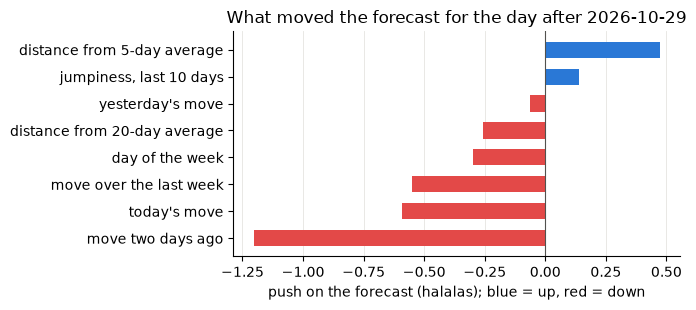

In [11]:
FEATURE_WORDS = {
    "ret_1d": "today's move", "ret_lag1": "yesterday's move", "ret_lag2": "move two days ago",
    "ret_5d": "move over the last week", "gap_ma5": "distance from 5-day average",
    "gap_ma20": "distance from 20-day average", "vol_10d": "jumpiness, last 10 days", "day_of_week": "day of the week",
}
scaler = loaded_model[0]
ridge = loaded_model[-1]
scaled = (example.values[0] - scaler.mean_) / scaler.scale_       # each input compared with an average day
push = pd.Series(ridge.coef_ * scaled * last_close * 100, index=FEATURES)   # in halalas
start = ridge.intercept_ * last_close * 100

why = pd.DataFrame({
    "input": [FEATURE_WORDS[f] for f in FEATURES],
    "value": [last_date.day_name() if f == "day_of_week" else f"{example[f].iloc[0] * 100:+.2f}%" for f in FEATURES],
    "push (halalas)": push.round(2).values,
}, index=FEATURES).sort_values("push (halalas)")
print(why.to_string())
print(f"Starting point {start:+.2f} + pushes {push.sum():+.2f} = {start + push.sum():+.2f} halalas -> forecast {pred_price:.3f} SAR")
if push.max() > 0:
    print(f"Biggest push up: {FEATURE_WORDS[push.idxmax()]} ({push.max():+.2f} halalas)")
if push.min() < 0:
    print(f"Biggest push down: {FEATURE_WORDS[push.idxmin()]} ({push.min():+.2f} halalas)")

order = push.sort_values()
plt.figure(figsize=(7, 3.2))
plt.barh([FEATURE_WORDS[f] for f in order.index], order.values,
         color=["#2a78d6" if v > 0 else "#e34948" for v in order.values], height=0.6)
plt.axvline(0, color="#52514e", linewidth=0.8)
plt.grid(axis="y", visible=False)
plt.gca().set_axisbelow(True)
plt.xlabel("push on the forecast (halalas); blue = up, red = down")
plt.title(f"What moved the forecast for the day after {last_date.date()}")
plt.tight_layout()
plt.show()

### Which inputs matter overall?
The weights below say how many halalas a forecast moves when an input is one "typical swing" above its usual level. Compare them with how much the real price moves in a day: tiny weights mean the model has learned that the recent past says very little about tomorrow.

In [12]:
overall = pd.DataFrame({
    "input": [FEATURE_WORDS[f] for f in FEATURES],
    "halalas per typical swing": (ridge.coef_ * last_close * 100).round(2),
    "when higher than usual": ["forecast up" if c > 0 else "forecast down" for c in ridge.coef_],
}, index=FEATURES)
overall = overall.reindex(overall["halalas per typical swing"].abs().sort_values(ascending=False).index)
print(overall.to_string())
print(f"For comparison, the real price moved {naive_mae * 100:.1f} halalas a day on average in the test period.")

                                    input  halalas per typical swing when higher than usual
ret_1d                       today's move                       2.07            forecast up
gap_ma5       distance from 5-day average                       0.91            forecast up
ret_5d            move over the last week                      -0.69          forecast down
ret_lag2                move two days ago                      -0.68          forecast down
gap_ma20     distance from 20-day average                      -0.56          forecast down
vol_10d           jumpiness, last 10 days                       0.26            forecast up
ret_lag1                 yesterday's move                       0.22            forecast up
day_of_week               day of the week                      -0.21          forecast down
For comparison, the real price moved 17.1 halalas a day on average in the test period.


## Your project starts here
1. **Clean architecture**: move the download, the features and the model out of this notebook into layers (domain, service, adapters), with the feature code written once.
2. **FastAPI endpoint**: a `POST /forecast` that returns the next-day forecast, the naive forecast and the top reasons.
3. **Container**: package the service and `artifacts/` into a Docker image.
4. **Tests**: unit tests for the features, and model-behaviour tests (for example: never far from today's price).
5. **GitHub Actions**: run the linter and the tests on every push and pull request.
6. **Secrets**: keep any key or token (a paid data feed, an API key for your own service) out of the code and out of git.
7. **Optional**: a small Vite + React front end that shows the forecast and its reasons.

The full guide is in [../../GUIDE.md](../../GUIDE.md).